# Project: Recommendation System - IBM Community

**Data Scientist Nanodegree - Master of Science in Artificial Intelligence**

**Udacity - October 22, 2026**

**Alaa Alaboud - Dhahran - KSA**

## Project Overview

This project develops article recommendation systems using user interaction data from the IBM Watson Studio platform. It explores user engagement and compares four recommendation approaches: rank-based recommendations, user-user collaborative filtering, content-based recommendations, and matrix factorization.

## Table of Contents

I. [Exploratory Data Analysis](#Exploratory-Data-Analysis)<br>
II. [Rank Based Recommendations](#Rank)<br>
III. [User-User Based Collaborative Filtering](#User-User)<br>
IV. [Content Based Recommendations](#Content-Recs)<br>
V. [Matrix Factorization](#Matrix-Fact)<br>
VI. [Extras & Concluding](#conclusions)

In [1]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import project_tests as t


df = pd.read_csv(
    'data/user-item-interactions.csv', 
    dtype={'article_id': int, 'title': str, 'email': str}
)
# Show df to get an idea of the data
df.head()

,Unnamed: 0,article_id,title,email
0,0,1430,"using pixiedust for fast, flexible, and easier...",ef5f11f77ba020cd36e1105a00ab868bbdbf7fe7
1,1,1314,healthcare python streaming application demo,083cbdfa93c8444beaa4c5f5e0f5f9198e4f9e0b
2,2,1429,use deep learning for image classification,b96a4f2e92d8572034b1e9b28f9ac673765cd074
3,3,1338,ml optimization using cognitive assistant,06485706b34a5c9bf2a0ecdac41daf7e7654ceb7
4,4,1276,deploy your python model as a restful api,f01220c46fc92c6e6b161b1849de11faacd7ccb2


In [2]:
# Remove the redundant index column and preview the first five rows
del df['Unnamed: 0']
df.head()

,article_id,title,email
0,1430,"using pixiedust for fast, flexible, and easier...",ef5f11f77ba020cd36e1105a00ab868bbdbf7fe7
1,1314,healthcare python streaming application demo,083cbdfa93c8444beaa4c5f5e0f5f9198e4f9e0b
2,1429,use deep learning for image classification,b96a4f2e92d8572034b1e9b28f9ac673765cd074
3,1338,ml optimization using cognitive assistant,06485706b34a5c9bf2a0ecdac41daf7e7654ceb7
4,1276,deploy your python model as a restful api,f01220c46fc92c6e6b161b1849de11faacd7ccb2


### <a class="anchor" id="Exploratory-Data-Analysis">Part I : Exploratory Data Analysis</a>


#### 1. Are there any missing values in the dataset, and how should missing emails be handled?

In [3]:
# Some interactions do not have a user associated with it, assume the same user.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45993 entries, 0 to 45992
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   article_id  45993 non-null  int64
 1   title       45993 non-null  str  
 2   email       45976 non-null  str  
dtypes: int64(1), str(2)
memory usage: 1.1 MB


In [4]:
# Count the number of missing values in the email column
print(f"Number of Null email values is: {df.email.isna().sum()}")

Number of Null email values is: 17


In [5]:
# Display rows with missing email values
df[df.email.isna()]

,article_id,title,email
25131,1016,why you should master r (even if it might even...,NaN
29758,1393,the nurse assignment problem,NaN
29759,20,working interactively with rstudio and noteboo...,NaN
29760,1174,breast cancer wisconsin (diagnostic) data set,NaN
29761,62,data visualization: the importance of excludin...,NaN
35264,224,"using apply, sapply, lapply in r",NaN
35276,961,beyond parallelize and collect,NaN
35277,268,sector correlations shiny app,NaN
35278,268,sector correlations shiny app,NaN
35279,268,sector correlations shiny app,NaN


In [6]:
# Fill missing email values with "unknown_user"
df['email'] = df['email'].fillna('unknown_user')

In [7]:
# Check if no more NaNs 
df[df.email.isna()]

,article_id,title,email


### Insight 1 

The `email` column contained **17** missing values. Since the email field is used to identify users in the recommendation system, these missing values were replaced with `"unknown_user"` to preserve the corresponding interaction records rather than removing them. A final check confirmed that no missing email values remained.

#### 2. How are user–article interactions distributed across users and articles?

In [8]:
# Count the number of interactions for each user
df['email'].value_counts()

email
2b6c0f514c2f2b04ad3c4583407dccd0810469ee    364
77959baaa9895a7e2bdc9297f8b27c1b6f2cb52a    363
2f5c7feae533ce046f2cb16fb3a29fe00528ed66    170
a37adec71b667b297ed2440a9ff7dad427c7ac85    169
8510a5010a5d4c89f5b07baac6de80cd12cfaf93    160
                                           ... 
a3f94d0fa042638f6ae5cdcd028e6d87884f1ee4      1
aee3c105b56256124382cd74624a993f2e840b6f      1
4faeed980a7cd11e0f3cf2058cc04daa2ef11452      1
abbf639ba05daa5249c520e290283a6d726ba78d      1
1f18e8aaccd6c8720180c3fe264c8aef5b00697f      1
Name: count, Length: 5149, dtype: int64

In [9]:
# Calculate descriptive statistics for user interaction counts
user_interaction_counts = df['email'].value_counts()
user_interaction_counts.describe()

count    5149.000000
mean        8.932414
std        16.801011
min         1.000000
25%         1.000000
50%         3.000000
75%         9.000000
max       364.000000
Name: count, dtype: float64

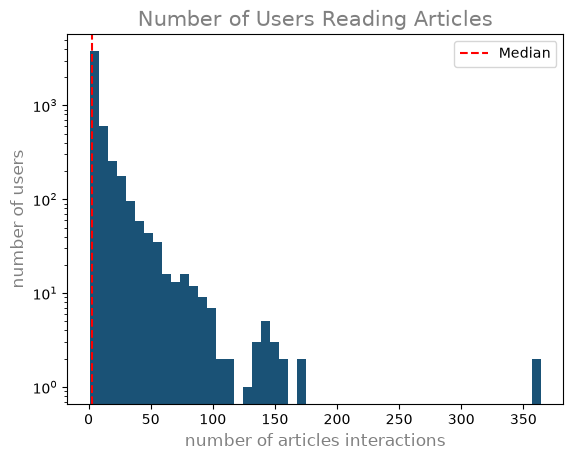

In [10]:
# Create a plot of the number of articles read by each user

plt.hist(user_interaction_counts, color='#1A5276', bins=50, log=True)

plt.xlabel('number of articles interactions', fontsize=12, color='grey')
plt.ylabel('number of users', fontsize=12, color='grey')
plt.title('Number of Users Reading Articles', fontsize=15, color='grey')

plt.axvline(user_interaction_counts.median(), linestyle='--', label='Median', color='red')
plt.legend()

plt.show()

In [11]:
# Calculate descriptive statistics for article interaction counts
article_interaction_counts = df['article_id'].value_counts()
article_interaction_counts.describe()

count    714.000000
mean      64.415966
std      109.175923
min        1.000000
25%        8.000000
50%       25.000000
75%       69.000000
max      937.000000
Name: count, dtype: float64

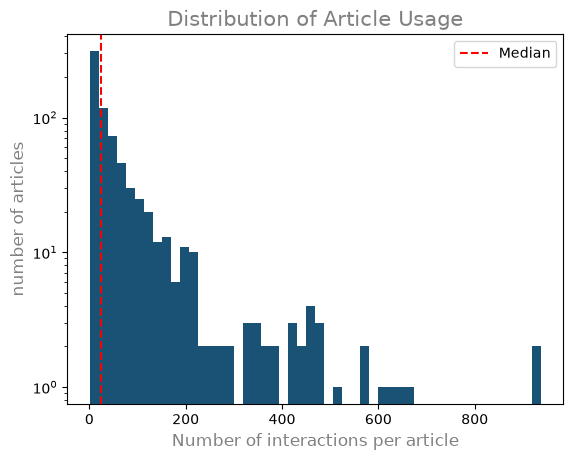

In [12]:
# Create a plot of the number of times each article was read

plt.hist(article_interaction_counts, color='#1A5276', bins=50, log=True)

plt.xlabel('Number of interactions per article', fontsize=12, color='grey')
plt.ylabel('number of articles', fontsize=12, color='grey')
plt.title('Distribution of Article Usage', fontsize=15, color='grey')

plt.axvline(article_interaction_counts.median(), linestyle='--', label='Median', color='red')
plt.legend()

plt.show()

In [13]:
# Calculate the median and maximum number of interactions per user

median_val =  int(user_interaction_counts.median()) # Median interactions per user
max_views_by_user =  user_interaction_counts.max() # Maximum interactions by a single user

print(f"50% of individuals interact with {median_val} number of articles or fewer.")
print(f"The maximum number of user-article interactions by any 1 user is {max_views_by_user}.")

50% of individuals interact with 3 number of articles or fewer.
The maximum number of user-article interactions by any 1 user is 364.


### Insight 2

The user interaction distribution is highly right-skewed. The median number of interactions per user is **3**, while the mean is approximately **8.93** and the maximum reaches **364** interactions. This indicates that most users interact with only a small number of articles, while a relatively small group of highly active users accounts for substantially more interactions.

Article popularity shows a similar right-skewed pattern. The median article receives **25** interactions, compared with an average of approximately **64.42**, while the most frequently accessed article reaches **937** interactions. This suggests that user attention is concentrated on a relatively small subset of highly popular articles.

Overall, both distributions indicate substantial variation in user activity and article popularity. This is important when designing the recommendation system, as interaction frequency alone may disproportionately favor already-popular articles and may not fully capture individual user preferences.

#### 3. How many unique articles, users, and user–article interactions does the dataset contain?

**a.** The number of unique articles that have an interaction with a user.  
**b.** The number of unique articles in the dataset (whether they have any interactions or not).<br>
**c.** The number of unique users in the dataset. (excluding null values) <br>
**d.** The number of user-article interactions in the dataset.

In [14]:
unique_articles =  df['article_id'].nunique() # The number of unique articles that have at least one interaction
total_articles = len(set(df['article_id'])) # The number of unique articles on the IBM platform
unique_users = df['email'].nunique() # The number of unique users
user_article_interactions =  df.shape[0] # The number of user-article interactions

print(f"The number of unique articles that have at least one interaction is {unique_articles}")
print(f"The number of unique articles on the IBM platform is {total_articles}.")
print(f"The number of unique users are {unique_users}.")
print(f"The number of user-article interactions is {user_article_interactions}.")

The number of unique articles that have at least one interaction is 714
The number of unique articles on the IBM platform is 714.
The number of unique users are 5149.
The number of user-article interactions is 45993.


### Insight 3

The dataset contains **45,993** user-article interactions associated with **5,149** user identifiers, including "unknown_user", involving **714** distinct articles with at least one recorded interaction. This indicates that the interaction history contains repeated engagement with articles rather than one interaction per user or article.

#### 4. Which article has the most recorded interactions, and how many interactions does it have?

The `email_mapper` function maps email addresses to numeric user IDs. Interactions with missing emails are grouped under a single user identifier.

In [15]:
# Calculate and rank article views by interaction count
article_views = df[['article_id', 'email']].groupby('article_id').count().sort_values('email', ascending=False)

article_views.head(10)

,email
article_id,
1429,937
1330,927
1431,671
1427,643
1364,627
1314,614
1293,572
1170,565
1162,512


In [16]:
most_viewed_article_id = f"{float(article_views.index[0]):.1f}" # The most viewed article in the dataset as a string with one value following the decimal 
print(f"The most viewed article in the dataset is: {most_viewed_article_id}") 

max_views = article_views['email'].iloc[0] # The most viewed article in the dataset was viewed how many times?
print(f"The most viewed article in the dataset was viewed {max_views} times.") 

The most viewed article in the dataset is: 1429.0
The most viewed article in the dataset was viewed 937 times.


In [17]:
# Map email addresses to numeric user IDs and remove the email column

def email_mapper(df=df):
    """
    Map each unique email address to a numeric user ID starting at 1.
    """
    coded_dict = {
        email: num 
        for num, email in enumerate(df['email'].unique(), start=1)
    }
    return [coded_dict[val] for val in df['email']]

df['user_id'] = email_mapper(df)
del df['email']

# show header
df.head()

,article_id,title,user_id
0,1430,"using pixiedust for fast, flexible, and easier...",1
1,1314,healthcare python streaming application demo,2
2,1429,use deep learning for image classification,3
3,1338,ml optimization using cognitive assistant,4
4,1276,deploy your python model as a restful api,5


In [18]:
# Convert the most viewed article ID to integer to match the provided test
most_viewed_article_id = int(article_views.index[0])

In [19]:
# Collect exploratory analysis results for validation

sol_1_dict = {
    '`50% of individuals have _____ or fewer interactions.`': median_val,
    '`The total number of user-article interactions in the dataset is ______.`': user_article_interactions,
    '`The maximum number of user-article interactions by any 1 user is ______.`': max_views_by_user,
    '`The most viewed article in the dataset was viewed _____ times.`': max_views,
    '`The article_id of the most viewed article is ______.`': most_viewed_article_id,
    '`The number of unique articles that have at least 1 rating ______.`': unique_articles,
    '`The number of unique users in the dataset is ______`': unique_users,
    '`The number of unique articles on the IBM platform`': total_articles
}

# Test your dictionary against the solution
t.sol_1_test(sol_1_dict)

It looks like you have everything right here! Nice job!


### Insight 4

Article **1429** is the most frequently viewed article in the dataset, with **937** interactions. This confirms that some articles receive substantially more engagement than others, which is consistent with the highly right-skewed article interaction distribution observed earlier.

### <a class="anchor" id="Rank">Part II: Rank-Based Recommendations</a>

In this project, we don't actually have ratings for whether a user liked an article or not.  We only know that a user has interacted with an article. In these cases, the popularity of an article can really only be based on how often an article was interacted with.

#### 1. Which articles are the most popular based on the number of recorded interactions?

In [20]:
# Display the top 10 most interacted-with articles by title
df['title'].value_counts().head(10)

title
use deep learning for image classification                            937
insights from new york car accident reports                           927
visualize car data with brunel                                        671
use xgboost, scikit-learn & ibm watson machine learning apis          643
predicting churn with the spss random tree algorithm                  627
healthcare python streaming application demo                          614
finding optimal locations of new store using decision optimization    572
apache spark lab, part 1: basic concepts                              565
analyze energy consumption in buildings                               512
gosales transactions for logistic regression model                    483
Name: count, dtype: int64

In [21]:
# Define functions to retrieve the top-ranked articles by interaction frequency

def get_top_articles(n, df=df):
    """
    INPUT:
    n - (int) the number of top articles to return
    df - (pandas dataframe) df as defined at the top of the notebook 
    
    OUTPUT:
    top_articles - (list) A list of the top 'n' article titles 
    
    """
    # Get the IDs of the top n most interacted-with articles
    top_article_ids = get_top_article_ids(n, df=df)
    
    # Initialize a list to store the corresponding article titles
    top_articles = []

    # Retrieve the title for each top article ID
    for article_id in top_article_ids:
        article_title = df.loc[df['article_id'] == article_id, 'title'].iloc[0]
        top_articles.append(article_title)
    
    return top_articles # Return the top article titles from df

def get_top_article_ids(n, df=df):
    """
    INPUT:
    n - (int) the number of top articles to return
    df - (pandas dataframe) df as defined at the top of the notebook 
    
    OUTPUT:
    top_articles - (list) A list of the top 'n' article IDs 
    
    """
    # Get the IDs of the top n most interacted-with articles
    top_articles = df['article_id'].value_counts().head(n).index.tolist()
    
    return top_articles # Return the top article ids

In [22]:
# Display the top 10 article titles and their corresponding IDs
print(get_top_articles(10))
print(get_top_article_ids(10))

['use deep learning for image classification', 'insights from new york car accident reports', 'visualize car data with brunel', 'use xgboost, scikit-learn & ibm watson machine learning apis', 'predicting churn with the spss random tree algorithm', 'healthcare python streaming application demo', 'finding optimal locations of new store using decision optimization', 'apache spark lab, part 1: basic concepts', 'analyze energy consumption in buildings', 'gosales transactions for logistic regression model']
[1429, 1330, 1431, 1427, 1364, 1314, 1293, 1170, 1162, 1304]


In [23]:
# Retrieve the top 5, 10, and 20 article titles
top_5 = get_top_articles(5)
top_10 = get_top_articles(10)
top_20 = get_top_articles(20)

# Validate ranked article recommendations against the expected results
t.sol_2_test(get_top_articles)

Your top_5 looks like the solution list! Nice job.
Your top_10 looks like the solution list! Nice job.
Your top_20 looks like the solution list! Nice job.


### Insight 5

The rank-based recommendation approach identifies the most popular articles based on the number of recorded user interactions. The results show that article **1429**, titled *“use deep learning for image classification”*, ranks first with **937 interactions**, followed by article **1330** with **927 interactions**.

This approach provides a simple way to recommend highly popular content, especially when no explicit user ratings are available. However, the recommendations are based on overall popularity rather than individual user preferences, meaning that all users would receive the same top-ranked articles.

### <a class="anchor" id="User-User">Part III: User-User Based Collaborative Filtering</a>


#### 1. How can user–article interactions be represented as a binary matrix with users as rows and articles as columns? 

* Each **user** should only appear in each **row** once.


* Each **article** should only show up in one **column**.  


* **If a user has interacted with an article, then place a 1 where the user-row meets for that article-column**.  It does not matter how many times a user has interacted with the article, all entries where a user has interacted with an article should be a 1.  


* **If a user has not interacted with an item, then place a zero where the user-row meets for that article-column**. 

The validation tests check the structure and binary values of the user–article matrix.

In [24]:
# create the user-article matrix with 1's and 0's

def create_user_item_matrix(df, fill_value=0):
    """
    INPUT:
    df - pandas dataframe with article_id, title, user_id columns
    
    OUTPUT:
    user_item - user item matrix 
    
    Description:
    Return a matrix with user ids as rows and article ids on the columns with 1 values where a user interacted with 
    an article and a 0 otherwise
    """
    # Build a binary user–article matrix
    user_item = df.pivot_table(
        index='user_id',
        columns='article_id',
        values='title',
        aggfunc=lambda x: 1
    ).fillna(fill_value).astype(int)
    
    return user_item # return the user_item matrix 

user_item = create_user_item_matrix(df)

In [67]:
# Validate the user–article matrix dimensions and save it as a pickle file
print(user_item.shape)
assert user_item.shape == (5149, 714)

user_item.to_pickle('user_item_matrix.p')

(5149, 714)


In [25]:
# Preview the first five users in the user-item matrix
user_item.head()

article_id,0,2,4,8,9,12,14,15,16,18,...,1434,1435,1436,1437,1439,1440,1441,1442,1443,1444
user_id,,,,,,,,,,,,,,,,,,,,,
1,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,1,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [26]:
# Validate matrix dimensions and the number of distinct articles read by user 1
assert user_item.shape[0] == 5149, "Oops!  The number of users in the user-article matrix doesn't look right."
assert user_item.shape[1] == 714, "Oops!  The number of articles in the user-article matrix doesn't look right."
assert user_item.sum(axis=1)[1] == 36, "Oops!  The number of articles seen by user 1 doesn't look right."
print("You have passed our quick tests!  Please proceed!")

You have passed our quick tests!  Please proceed!


### Insight 6

The user-item matrix contains **5,149** user identifiers, including "unknown_user", and **714** articles. Each value is binary: **1** indicates that a user interacted with an article, while **0** indicates no recorded interaction. Repeated interactions with the same article are represented by a single 1, so the matrix captures whether an interaction occurred rather than its frequency. User 1, for example, interacted with **36 distinct articles**. This matrix provides the basis for comparing users by their article interaction patterns.

#### 2. Which users have the most similar article interaction patterns to a given user?

Users are ranked from most to least similar, excluding the target user from the results.

In [27]:
# Lets use the cosine_similarity function from sklearn
from sklearn.metrics.pairwise import cosine_similarity

In [28]:
def find_similar_users(user_id, user_item=user_item, include_similarity=False):
    """
    INPUT:
    user_id - (int) a user_id
    user_item - (pandas dataframe) matrix of users by articles: 
                1's when a user has interacted with an article, 0 otherwise
    include_similarity - (bool) whether to include the similarity in the output
    
    OUTPUT:
    similar_users - (list) user IDs ordered by descending cosine similarity,
                excluding the target user
    
    Description:
    Computes cosine similarity between the target user and all users in the user-item matrix.
    Returns an ordered list of user ids. If include_similarity is True, returns a list of lists
    where the first element is the user id and the second the similarity.
    
    """
    
    # compute similarity of each user to the provided user
    similarities = pd.Series(
    cosine_similarity(user_item.loc[[user_id]], user_item)[0],
    index=user_item.index
    )

    # sort by similarity
    similarity_scores = similarities.sort_values(ascending=False)
    
    # remove the own user's id
    similarity_scores = similarity_scores.drop(user_id)

    # create list of just the ids
    most_similar_users = similarity_scores.index.tolist()

    # create list of just the similarities
    similarity_values = similarity_scores.tolist()

    
    if include_similarity:
        return [[uid, score] for uid, score in zip(most_similar_users, similarity_values)] # return a list of lists with [[similar_user_id, similarity], ...]
    return most_similar_users # return a list of the users in order from most to least similar  

In [29]:
# Do a spot check of your function
print("The 10 most similar users to user 1 are: {}".format(find_similar_users(1)[:10]))
print("The 5 most similar users to user 3933 are: {}".format(find_similar_users(3933)[:5]))
print("The 3 most similar users to user 46 are: {}".format(find_similar_users(46)[:3]))

The 10 most similar users to user 1 are: [3933, 46, 4201, 253, 5034, 824, 5041, 2305, 136, 395]
The 5 most similar users to user 3933 are: [1, 4201, 46, 253, 824]
The 3 most similar users to user 46 are: [4201, 790, 5077]


### Insight 7

The user-user collaborative filtering approach uses **cosine similarity** between binary user-item interaction vectors. Higher scores indicate greater overlap in the articles users interacted with, relative to the number of distinct articles each user interacted with.

The results show that user **3933** is the most similar user to user **1**, while user **1** is the most similar user to user **3933**. User **4201** is the closest match for user **46**.

The target user is excluded from the results, and users with equal similarity scores may appear in different orders. These similarities provide a foundation for recommending articles that the target user has not yet interacted with.

#### 3. How can similar users help recommend articles that the target user has not yet interacted with?

In [30]:
# Retrieve the article titles corresponding to the provided article IDs.
def get_article_names(article_ids, df=df):
    """
    INPUT:
    article_ids - (list) a list of article ids
    df - (pandas dataframe) df as defined at the top of the notebook
    
    OUTPUT:
    article_names - (list) a list of article names associated with the list of article ids 
                    (this is identified by the title column in df)
    """

    # Initialize a list to store article titles
    article_names = []

    # Retrieve the corresponding title for each article ID
    for article_id in article_ids:
        article_name = df.loc[df['article_id'] == article_id, 'title'].iloc[0]
        article_names.append(article_name)
    
    
    return article_names # Return the article names associated with list of article ids

# Count unique users per article and rank the results in descending order.
def get_ranked_article_unique_counts(article_ids, user_item=user_item):
    """
    INPUT:
    article_ids - (list) a list of article ids to evaluate (a subset to rank).
                the dtype should match the column labels in `user_item`.
    user_item - (pandas dataframe) a binary matrix of users by articles [n_users x n_articles]:
                1's when a user has interacted with an article, 0 otherwise 
                columns are article IDs.
    
    OUTPUT:
    ranked_article_unique_counts - (list) a list of tuples [(article_id, unique_user_count)]
                     only for the provided `article_ids` with article_id and number of unique
                     users that have interacted with the article, sorted by the number of unique
                     users in descending order
    
    Description:
    For each `article_id` in the input list, count the number of unique users who
    interacted with it (column sum in the binary `user_item` matrix).
    Return the (article_id, count) pairs sorted in descending order.
    """
    
    # Initialize a list to store article IDs and unique user counts
    ranked_article_unique_counts = []

    # Count unique users who interacted with each article
    for article_id in article_ids:
        unique_user_count = user_item[article_id].sum()
        ranked_article_unique_counts.append([article_id, int(unique_user_count)])

    # Sort articles by unique user count in descending order
    ranked_article_unique_counts.sort(
    key=lambda item: item[1],
    reverse=True
    )

    return ranked_article_unique_counts

# Retrieve the IDs and titles of articles previously viewed by the specified user.
def get_user_articles(user_id, user_item=user_item):
    """
    INPUT:
    user_id - (int) a user id
    user_item - (pandas dataframe) matrix of users by articles: 
                1's when a user has interacted with an article, 0 otherwise
    
    OUTPUT:
    article_ids - (list) a list of the article ids seen by the user
    article_names - (list) a list of article names associated with the list of article ids 
                    (this is identified by the title column in df)
    
    Description:
    Provides a list of the article_ids and article titles that have been seen by a user
    """

    # Get the target user's article interactions
    user_articles = user_item.loc[user_id]

    # Extract the IDs of articles the user has interacted with
    article_ids = user_articles[user_articles == 1].index.tolist()
    
    # Retrieve titles using the existing helper function
    article_names = get_article_names(article_ids)
    
    return article_ids, article_names # return the ids and names

# Recommend unseen articles from similar users, avoiding duplicates and limiting results to m.
def user_user_recs(user_id, m=10):
    """
    INPUT:
    user_id - (int) a user id
    m - (int) the number of recommendations you want for the user
    
    OUTPUT:
    recs - (list) a list of recommendations for the user
    
    Description:
    Loops through the users based on closeness to the input user_id
    For each user - finds articles the user hasn't seen before and provides them as recs
    Does this until m recommendations are found
    
    Notes:
    Users who are the same closeness are chosen arbitrarily as the 'next' user
    
    For the user where the number of recommended articles starts below m 
    and ends exceeding m, the last items are chosen arbitrarily
    
    """
    
    # Initialize an empty list to store recommended article IDs
    recs = []

    # Get articles already seen by the target user
    user_articles, _ = get_user_articles(user_id)
    
    # Find users with similar article interactions
    similar_users = find_similar_users(user_id)
    
    # Collect unseen articles from similar users without duplicates
    for similar_user in similar_users: 
        similar_user_articles, _ = get_user_articles(similar_user)
        new_articles = [
            article_id for article_id in similar_user_articles
            if article_id not in user_articles
        ]
    # Add unique article recommendations and stop when the requested number is reached
        for article_id in new_articles:
            if article_id not in recs:
                recs.append(article_id)
    
            if len(recs) >= m:
                return recs[:m]
    # Limit the final recommendations to the requested number
    recs = recs[:m]
        
    
    return recs # return your recommendations for this user_id    

In [31]:
# Check Results - get_article_names()
get_article_names([1024, 1176, 1305])

['using deep learning to reconstruct high-resolution audio',
 'build a python app on the streaming analytics service',
 'gosales transactions for naive bayes model']

In [32]:
# Check Results - get_user_articles()
get_user_articles(20)

([232, 844, 1320],
 ['self-service data preparation with ibm data refinery',
  'use the cloudant-spark connector in python notebook',
  'housing (2015): united states demographic measures'])

In [33]:
# Check Results - user_user_recs() 
get_article_names(user_user_recs(1, 10)) # Return 10 recommendations for user 1

['this week in data science (april 18, 2017)',
 'this week in data science (may 2, 2017)',
 'top 20 r machine learning and data science packages',
 'improving the roi of big data and analytics through leveraging new sources of data',
 'using apply, sapply, lapply in r',
 'awesome deep learning papers',
 'leverage python, scikit, and text classification for behavioral profiling',
 'challenges in deep learning',
 'do i need to learn r?',
 'how can data scientists collaborate to build better business']

In [34]:
len(user_user_recs(1, 10))

10

In [35]:
# Check Results - get_ranked_article_unique_counts()
get_ranked_article_unique_counts([1320, 232, 844])

[[1320, 123], [844, 78], [232, 62]]

In [36]:
# Validate article lookup, user history, and unique-user article counts
assert set(get_article_names([1024, 1176, 1305, 1314, 1422, 1427])) == set(['using deep learning to reconstruct high-resolution audio', 'build a python app on the streaming analytics service', 'gosales transactions for naive bayes model', 'healthcare python streaming application demo', 'use r dataframes & ibm watson natural language understanding', 'use xgboost, scikit-learn & ibm watson machine learning apis']), "Oops! Your the get_article_names function doesn't work quite how we expect."
assert set(get_article_names([1320, 232, 844])) == set(['housing (2015): united states demographic measures','self-service data preparation with ibm data refinery','use the cloudant-spark connector in python notebook']), "Oops! Your the get_article_names function doesn't work quite how we expect."
assert set(get_user_articles(20)[0]) == set([1320, 232, 844])
assert set(get_user_articles(20)[1]) == set(['housing (2015): united states demographic measures', 'self-service data preparation with ibm data refinery','use the cloudant-spark connector in python notebook'])
assert set(get_user_articles(2)[0]) == set([1024, 1176, 1305, 1314, 1422, 1427])
assert set(get_user_articles(2)[1]) == set(['using deep learning to reconstruct high-resolution audio', 'build a python app on the streaming analytics service', 'gosales transactions for naive bayes model', 'healthcare python streaming application demo', 'use r dataframes & ibm watson natural language understanding', 'use xgboost, scikit-learn & ibm watson machine learning apis'])
assert get_ranked_article_unique_counts([1320, 232, 844])[0] == [1320, 123], "Oops! Your the get_ranked_article_unique_counts function doesn't work quite how we expect.\nMake sure you are using the user_item matrix to create the article counts."
print("If this is all you see, you passed all of our tests!  Nice job!")

If this is all you see, you passed all of our tests!  Nice job!


### Insight 8

The user-user collaborative filtering approach generates personalized article recommendations by identifying users with similar interaction histories.

The recommendation function retrieves articles from similar users while excluding articles the target user has already interacted with. It also prevents duplicate recommendations and limits the results to the requested number of articles.

Additionally, article popularity can be measured by counting the number of unique users who interacted with each article. For example, articles **1320**, **844**, and **232** were associated with **123**, **78**, and **62** unique users, respectively.

All provided tests for the recommendation helper functions passed successfully, confirming that the functions produce the expected outputs.

#### 4. How can user activity and article popularity help prioritize recommendations when similarity scores are tied?

* Instead of arbitrarily choosing when we obtain users who are all the same closeness to a given user - choose the users that have the most total article interactions before choosing those with fewer article interactions.


* Instead of arbitrarily choosing articles from the user where the number of recommended articles starts below m and ends exceeding m, choose articles with the articles with the most total interactions before choosing those with fewer total interactions. This ranking should be  what would be obtained from the **top_articles** function.

In [37]:
# Identify and rank similar users by similarity score and total article interactions.
def get_top_sorted_users(user_id, user_item=user_item):
    """
    INPUT:
    user_id - (int)
    user_item - (pandas dataframe) matrix of users by articles: 
            1's when a user has interacted with an article, 0 otherwise
    
            
    OUTPUT:
    neighbors_df - (pandas dataframe) a dataframe with:
                    neighbor_id - is a neighbor user_id
                    similarity - measure of the similarity of each user to the provided user_id
                    num_interactions - the number of articles viewed by the user
                    
    Other Details - sort the neighbors_df by the similarity and then by number of interactions where 
                    highest of each is higher in the dataframe, i.e. Descending order
     
    """
    
    # Initialize an empty DataFrame for similar users.
    neighbors_df = pd.DataFrame()
    
    # Get similar users and their similarity scores.
    similar_users = find_similar_users(user_id, user_item, include_similarity=True)

    # Add similar users and their similarity scores to the DataFrame.
    neighbors_df[['neighbor_id', 'similarity']] = pd.DataFrame(
        similar_users,
        columns=['neighbor_id', 'similarity']
    )

    # Count distinct articles each similar user interacted with
    neighbors_df['num_interactions'] = (
    neighbors_df['neighbor_id']
    .map(user_item.sum(axis=1))
    .astype(int)
    )

    # Sort users by similarity, then by total interactions.
    neighbors_df = neighbors_df.sort_values(
        by=['similarity', 'num_interactions'],
        ascending=[False, False]
    ).reset_index(drop=True)

    return neighbors_df # Return the dataframe specified in the doc_string
 

def user_user_recs_part2(user_id, m=10):
    """
    INPUT:
    user_id - (int) a user id
    m - (int) the number of recommendations you want for the user
    
    OUTPUT:
    recs - (list) a list of recommendations for the user by article id
    rec_names - (list) a list of recommendations for the user by article title
    
    Description:
    Loops through the users based on closeness to the input user_id
    For each user - finds articles the user hasn't seen before and provides them as recs
    Does this until m recommendations are found
    
    Notes:
    * Choose the users that have the most total article interactions 
    before choosing those with fewer article interactions.

    * Choose articles with the articles with the most total interactions 
    before choosing those with fewer total interactions. 
   
    """
    
    recs = []

    # Get articles already viewed by the target user.
    user_articles, _ = get_user_articles(user_id)
        
    # Retrieve similar users ranked by similarity and interaction count.
    neighbors_df = get_top_sorted_users(user_id)

    # Rank candidate articles by their total interaction counts.
    article_counts = df['article_id'].value_counts()

    # Iterate through similar users in ranked order.
    for neighbor_id in neighbors_df['neighbor_id']:

        # Get articles viewed by the current neighbor.
        neighbor_articles, _ = get_user_articles(neighbor_id)
        
        # Find articles the target user has not viewed.
        new_articles = list(set(neighbor_articles) - set(user_articles))

        # Sort articles by total interaction count.
        new_articles = sorted(
            new_articles,
            key=lambda article_id: article_counts.get(float(article_id), 0),
            reverse=True
        )

        # Add unseen articles without duplicates, up to the requested limit.
        for article_id in new_articles:
            if article_id not in recs:
                recs.append(article_id)
        
            if len(recs) >= m:
                break
        
        if len(recs) >= m:
            break
    
    return recs, get_article_names(recs) # return your recommendations for this user_id

In [38]:
# Check Results - get_top_sorted_users()
get_top_sorted_users(1).head(10)

,neighbor_id,similarity,num_interactions
0,3933,0.986013,35
1,46,0.342580,40
2,4201,0.342580,40
3,253,0.333333,4
4,5034,0.333333,4
5,824,0.333333,4
6,5041,0.301511,44
7,2305,0.298142,5
8,136,0.298142,5
9,395,0.294884,46


In [39]:
# Preview 10 recommended article IDs and titles for user 20
rec_ids, rec_names = user_user_recs_part2(20, 10)
print("The top 10 recommendations for user 20 are the following article ids:")
print(rec_ids)
print()
print("The top 10 recommendations for user 20 are the following article names:")
print(rec_names)

The top 10 recommendations for user 20 are the following article ids:
[1293, 1185, 1165, 254, 1162, 1271, 1328, 1410, 40, 1402]

The top 10 recommendations for user 20 are the following article names:
['finding optimal locations of new store using decision optimization', 'classify tumors with machine learning', 'analyze precipitation data', 'apple, ibm add machine learning to partnership with watson-core ml coupling', 'analyze energy consumption in buildings', 'customer demographics and sales', 'income (2015): united states demographic measures', 'uci: sms spam collection', 'ensemble learning to improve machine learning results', 'uci: adult - predict income']


### Insight 9

The improved recommendation system prioritizes similar users based on their similarity scores, breaking ties by the number of distinct articles each user interacted with. It then recommends popular articles that the target user has not previously viewed, while avoiding duplicate recommendations.

The initial spot check for User **20** successfully returned **10** article IDs and their corresponding titles. However, further evaluation is needed to determine whether these improvements increase recommendation quality.


#### 5. Which users are most similar to users 1, 2, and 131, and do the results match the expected outputs?

In [40]:
# Display the most similar users to users 1, 2, and 131
print(get_top_sorted_users(1, user_item=user_item).head(n=1))
print(get_top_sorted_users(2, user_item=user_item).head(n=10))
print(get_top_sorted_users(131, user_item=user_item).head(n=10))

   neighbor_id  similarity  num_interactions
0         3933    0.986013                35
   neighbor_id  similarity  num_interactions
0         5083    0.730297                 5
1         1890    0.577350                 2
2         1552    0.577350                 2
3         1372    0.471405                 3
4         2941    0.433013                 8
5         3586    0.408248                 4
6         2595    0.408248                 1
7          861    0.408248                 1
8         2648    0.408248                 1
9         1660    0.408248                 1
   neighbor_id  similarity  num_interactions
0         3870    0.986667                75
1         4459    0.388909                96
2          203    0.388909                96
3         3782    0.387585               135
4         4932    0.384308                52
5           40    0.384308                52
6           23    0.377647               135
7          242    0.375823                59
8         

In [41]:
# Extract the 1st, 6th, and 10th ranked neighbors for users 1, 2, and 131, respectively
user1_most_sim = get_top_sorted_users(1).iloc[0]['neighbor_id'] # Find the user that is most similar to user 1 
user2_6th_sim = get_top_sorted_users(2).iloc[5]['neighbor_id'] # Find the 6th most similar user to user 2
user131_10th_sim = get_top_sorted_users(131).iloc[9]['neighbor_id'] # Find the 10th most similar user to user 131

In [42]:
# Validate selected user similarity rankings
sol_5_dict = {
    'The user that is most similar to user 1.': user1_most_sim, 
    'The user that is the 6th most similar to user 2.': user2_6th_sim,
    'The user that is the 10th most similar to user 131.': user131_10th_sim,
}

t.sol_5_test(sol_5_dict)

This all looks good!  Nice job!


### Insight 10

The selected user rankings passed the provided dictionary test. The test checks the most similar user to user **1**, the sixth-ranked user for user **2**, and the tenth-ranked user for user **131**. This confirms that these selected results match the expected outputs, but does not establish the quality of the article recommendations.

#### 6. How can articles be recommended to a new user with no interaction history, and how could these recommendations become personalized over time?

For a new user, I would use **get_top_articles** or **get_top_article_ids** to provide **rank-based** recommendations, because user-user collaborative filtering requires previous interactions to identify similar users.

A better approach is to recommend the most popular articles based on total interactions as a starting point. As the new user begins interacting with articles, we can gradually incorporate collaborative filtering and personalize the recommendations.

#### 7. Which 10 articles can be recommended to a new user with no interaction history?

In [43]:
# What would your recommendations be for this new user 0?  As a new user, they have no observed articles.
# Provide a list of the top 10 article ids you would give to 
new_user_recs = get_top_article_ids(10) # Recommend the 10 most popular articles to a new user

In [44]:
assert set(new_user_recs) == {1314, 1429, 1293, 1427, 1162, 1364, 1304, 1170, 1431, 1330}, "Oops!  It makes sense that in this case we would want to recommend the most popular articles, because we don't know anything about these users."

print("That's right!  Nice job!")

That's right!  Nice job!


### <a class="anchor" id="Content-Recs">Part IV: Content Based Recommendations</a>

Another method we might use to make recommendations is to recommend similar articles that are possibly related. One way we can find article relationships is by clustering text about those articles.  Let's consider content to be the article **title**, as it is the only text we have available. One point to highlight, there isn't one way to create a content based recommendation, especially considering that text information can be processed in many ways.

#### 1. How can TF-IDF and clustering of article titles be used to recommend related articles?

In [45]:
df.head()

,article_id,title,user_id
0,1430,"using pixiedust for fast, flexible, and easier...",1
1,1314,healthcare python streaming application demo,2
2,1429,use deep learning for image classification,3
3,1338,ml optimization using cognitive assistant,4
4,1276,deploy your python model as a restful api,5


In [46]:
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from sklearn.decomposition import TruncatedSVD

In [47]:
# Get unique articles based on article_id.
df_unique_articles = df.drop_duplicates(subset=['article_id']).copy()

In [48]:
# Create a vectorizer using TfidfVectorizer and fit it to the article titles
max_features = 200
max_df = 0.75
min_df = 5

vectorizer = TfidfVectorizer(
    max_df=max_df,
    min_df=min_df,
    stop_words="english",
    max_features=max_features,
)
print("Running TF-IDF")
X_tfidf = vectorizer.fit_transform(df_unique_articles['title']) # Fit the vectorizer to the article titles

print(f"n_samples: {X_tfidf.shape[0]}, n_features: {X_tfidf.shape[1]}")

lsa = make_pipeline(TruncatedSVD(n_components=50), Normalizer(copy=False))
X_lsa = lsa.fit_transform(X_tfidf) # Fit the LSA model to the vectorized article titles
explained_variance = lsa[0].explained_variance_ratio_.sum()

print(f"Explained variance of the SVD step: {explained_variance * 100:.1f}%")

Running TF-IDF
n_samples: 714, n_features: 125
Explained variance of the SVD step: 76.0%


Text(0, 0.5, 'Inertia')

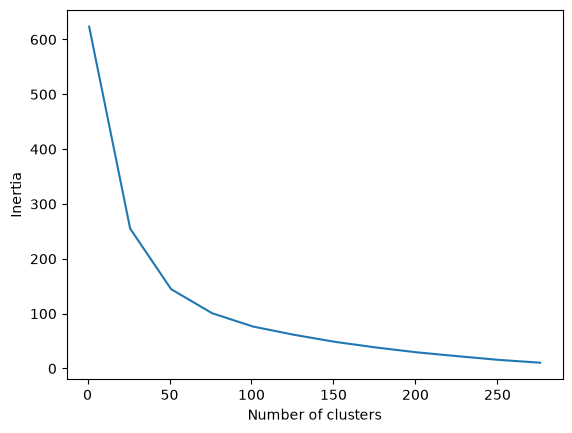

In [49]:
# Let's map the inertia for different number of clusters to find the optimal number of clusters
# We'll plot it to see the elbow
inertia = []
clusters = 300
step = 25
max_iter = 50
n_init = 5
random_state = 42
for k in range(1, clusters, step):
    kmeans = KMeans(
        n_clusters=k,
        max_iter=max_iter,
        n_init=n_init,
        random_state=random_state,
    ).fit(X_lsa)
    # inertia is the sum of squared distances to the closest cluster center
    inertia.append(kmeans.inertia_)
plt.plot(range(1, clusters, step), inertia)
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')

There appears to be an elbow about 50, so we'll use 50 clusters.

In [50]:
# Fit KMeans with 50 clusters on the reduced article-title features
n_clusters = 50 # Number of clusters
kmeans = KMeans(
    n_clusters=n_clusters,
    max_iter=max_iter,
    n_init=n_init,
    random_state=random_state
).fit(X_lsa)

In [51]:
# create a new column `title_cluster` and assign it the kmeans cluster labels
# First we need to map the labels to df_unique_articles article ids and then apply those to df
article_cluster_map = {article_id: cluster
    for article_id, cluster in zip(df_unique_articles['article_id'], kmeans.labels_)} # Map article_id to cluster label
df['title_cluster'] = df['article_id'].map(article_cluster_map) # apply map to create title clusters

In [52]:
# Let's check the number of articles in each cluster
np.array(np.unique(kmeans.labels_, return_counts=True)).T

array([[ 0, 12],
       [ 1, 30],
       [ 2,  7],
       [ 3, 67],
       [ 4, 35],
       [ 5, 13],
       [ 6, 18],
       [ 7, 20],
       [ 8, 19],
       [ 9, 28],
       [10, 11],
       [11, 19],
       [12,  8],
       [13, 36],
       [14, 23],
       [15, 13],
       [16, 10],
       [17, 11],
       [18,  5],
       [19, 16],
       [20, 10],
       [21, 13],
       [22, 22],
       [23,  1],
       [24, 18],
       [25, 22],
       [26,  9],
       [27, 23],
       [28,  8],
       [29, 12],
       [30,  8],
       [31, 13],
       [32,  8],
       [33, 14],
       [34,  5],
       [35,  9],
       [36,  9],
       [37, 13],
       [38,  9],
       [39, 10],
       [40, 10],
       [41,  7],
       [42,  6],
       [43, 11],
       [44,  8],
       [45,  7],
       [46,  4],
       [47,  4],
       [48,  9],
       [49, 11]])

In [53]:
def get_similar_articles(article_id, df=df):
    """
    INPUT:
    article_id - (int) an article id 
    df - (pandas dataframe) df as defined at the top of the notebook 
    
    OUTPUT:
    article_ids - (list) a list of article ids that are in the same title cluster
    
    Description:
    Returns a list of the article ids that are in the same title cluster
    """
    
    # Find the cluster of the input article
    title_cluster = df.loc[
        df['article_id'] == article_id, 'title_cluster'
    ].iloc[0]
    
    # Get unique articles from the same cluster
    articles_in_cluster = df.loc[
        df['title_cluster'] == title_cluster, 'article_id'
    ].unique().tolist()
    
    # Remove the input article_id from the list
    articles_in_cluster.remove(article_id)
    
    return articles_in_cluster

In [54]:
def make_content_recs(article_id, n, df=df):
    """
    INPUT:
    article_id - (int) an article id
    n - (int) the number of recommendations you want similar to the article id
    df - (pandas dataframe) df as defined at the top of the notebook
    
    OUTPUT:
    n_ranked_similar_articles - (list) a list of article ids that are in the same title cluster ranked
                                by popularity
    n_ranked_article_names - (list) a list of article names associated with the list of article ids
    
    Description:
    Returns a list of the n most ranked similar articles to a given article_id based on the title
    cluster in df. Rank similar articles using the function get_ranked_article_unique_counts.
    """

    # Get similar articles from the same title cluster.
    similar_articles = get_similar_articles(article_id, df)
    
    # Rank similar articles by popularity.
    ranked_articles = get_ranked_article_unique_counts(
        similar_articles
    )

    # Keep only similar articles, preserving popularity order.
    ranked_similar_articles = [
        article_id for article_id, count in ranked_articles
        if article_id in similar_articles
    ]

    # Select the top n similar articles.
    n_ranked_similar_articles = ranked_similar_articles[:n]

    # Retrieve titles using the existing helper function
    n_ranked_article_names = get_article_names(n_ranked_similar_articles, df=df)

    
    return n_ranked_similar_articles, n_ranked_article_names

In [55]:
# Display 10 content-based recommendations for article 25
rec_article_ids, rec_article_titles = make_content_recs(25, 10)
print(rec_article_ids)
print(rec_article_titles)

[1025, 101, 975, 766, 508, 547, 132, 878, 92, 693]
['data tidying in data science experience', 'how to choose a project to practice data science', 'the data science process', 'making data science a team sport', 'data science in the cloud', 'trust in data science', 'collecting data science cheat sheets', '10 data science podcasts you need to be listening to right now', '9 mistakes to avoid when starting your career in data science', 'better together: spss and data science experience']


In [56]:
assert len({1025, 593, 349, 821, 464, 29, 1042, 693, 524, 352}.intersection(set(rec_article_ids))) > 0, "Oops! Your the make_content_recs function doesn't work quite how we expect."

#### 2. How does the content-based recommender work, what improvements could be made, and what additional text data could improve its recommendations?

### Insight 11

The content-based recommendation system uses TF-IDF to convert article titles into numerical features, followed by TruncatedSVD to reduce dimensionality. K-Means clustering groups articles with similar title content.

When an article is selected, the system identifies other articles in the same cluster, excludes the original article, and ranks the recommendations by popularity based on the number of distinct users who interacted with each article..

**Possible improvements:** The system could use cosine similarity to rank articles by their individual similarity scores instead of relying only on cluster membership. Additional text data, such as article descriptions, abstracts, keywords, and full article content, could improve recommendation relevance.

### <a class="anchor" id="Matrix-Fact">Part V: Matrix Factorization</a>

Matrix factorization represents user–article interaction patterns through latent features to support article recommendations.

#### 1. What does the user–item matrix used for matrix factorization look like? 

In [57]:
# quick look at the matrix
user_item.head()

article_id,0,2,4,8,9,12,14,15,16,18,...,1434,1435,1436,1437,1439,1440,1441,1442,1443,1444
user_id,,,,,,,,,,,,,,,,,,,,,
1,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,1,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


#### 2. How can Singular Value Decomposition (SVD) be applied to the user–item matrix?

In [58]:
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import precision_score, recall_score, accuracy_score
# Using the full number of components which equals the number of columns
svd = TruncatedSVD(n_components=len(user_item.columns), n_iter=5, random_state=42)

# fit_transform returns UΣ; components_ contains Vᵀ
u = svd.fit_transform(user_item)
v = svd.components_
s = svd.singular_values_ 
print('u', u.shape)
print('s', s.shape)
print('vt', v.shape)

u (5149, 714)
s (714,)
vt (714, 714)


### Insight 12

SVD can be applied because the user–item matrix is numerical and contains no missing values: 1 represents a recorded interaction and 0 represents no recorded interaction. A low-rank approximation captures latent interaction patterns, although zeros do not necessarily indicate dislike.

In this implementation, `u` contains UΣ, `s` contains the singular values, and `v` contains Vᵀ. Therefore, the matrix is reconstructed using `u @ v`.

#### 3. How does the number of latent features affect reconstruction accuracy, precision, and recall for the user–item matrix?

Text(0.5, 1.0, 'Metrics vs. Number of Latent Features')

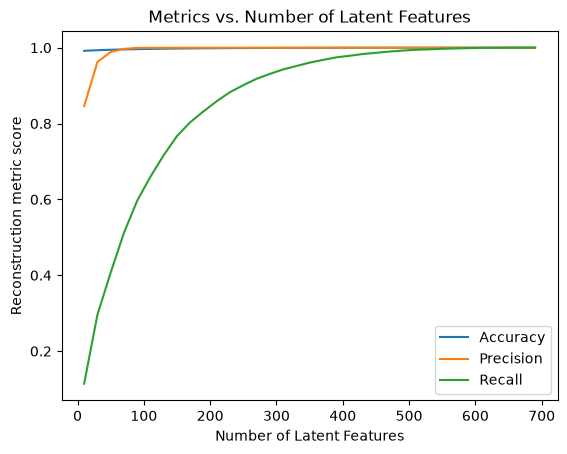

In [59]:
# Evaluate user–item matrix reconstruction across different numbers of latent features
num_latent_feats = np.arange(10, 700+10, 20)
metric_scores = []

for k in num_latent_feats:
    # restructure with k latent features
    u_new, vt_new = u[:, :k], v[:k, :]
    
    # take dot product
    user_item_est = abs(np.around(np.dot(u_new, vt_new))).astype(int)
    # make sure the values are between 0 and 1
    user_item_est = np.clip(user_item_est, 0, 1)
    
    # total errors and keep track of them
    acc = accuracy_score(user_item.values.flatten(), user_item_est.flatten())
    precision = precision_score(user_item.values.flatten(), user_item_est.flatten())
    recall = recall_score(user_item.values.flatten(), user_item_est.flatten())
    metric_scores.append([acc, precision, recall])
    
    
plt.plot(num_latent_feats, metric_scores, label=['Accuracy', 'Precision', 'Recall'])
plt.legend()
plt.xlabel('Number of Latent Features')
plt.ylabel('Reconstruction metric score')
plt.title('Metrics vs. Number of Latent Features')

#### 4. Better reconstruction of the user–item matrix does not necessarily imply better recommendations. Based on the plot, how many latent features provide a reasonable balance between reconstruction performance and model complexity, and what are the limitations of this choice?

### Insight 13

Based on the plot, I would initially choose **200** latent features as a balance between model complexity and performance. Accuracy and precision are already high, while recall improves substantially compared to using fewer features.

However, these metrics are calculated on the existing user-item matrix and do not necessarily indicate recommendation quality for unseen interactions. A more reliable choice would require evaluating different numbers of latent features on held-out data using recommendation metrics.

#### 5. How can 200 latent features from SVD be used to recommend similar articles using cosine similarity?

In [60]:
def get_svd_similar_article_ids(article_id, vt, user_item=user_item, include_similarity=False):
    """
    INPUT:
    article_id - (int) an article id
    vt - (numpy array) vt matrix from SVD
    user_item - (pandas dataframe) matrix of users by articles: 
                1's when a user has interacted with an article, 0 otherwise
    include_similarity - (bool) whether to include the similarity in the output
    
    OUTPUT:
    article_ids - (list) the 10 most similar article IDs based on SVD and cosine similarity
    If include_similarity is True, returns [article_id, similarity_score] pairs instead.
    
    Description:
    Returns a list of the article ids similar using SVD factorization
    """
    # Find the index of the article_id
    article_idx = user_item.columns.get_loc(article_id)
    
    # Find the cosine similarity of all articles
    cos_sim = cosine_similarity(vt.T)
    
    # Get similarities only for the cos_sim of the article_idx
    article_similarities = cos_sim[article_idx]
    
    # Sort and return the articles, don't include the own article
    sorted_indices = np.argsort(article_similarities)[::-1]

    # Exclude the input article from recommendations.
    sorted_indices = sorted_indices[sorted_indices != article_idx]

    # Convert sorted indices to article IDs.
    similar_article_ids = user_item.columns[sorted_indices].tolist()

    # Select the top 10 similar articles.
    similar_article_ids = similar_article_ids[:10]

    # Prepare article IDs and similarity scores.
    most_similar_items = similar_article_ids
    similarity_items = [
        [article_id, float(article_similarities[user_item.columns.get_loc(article_id)])]
        for article_id in similar_article_ids
    ]
    
    if include_similarity:
        return similarity_items # return a list of lists with [[similar_article_id, similarity], ...]
    return most_similar_items

In [61]:
# Create a vt_new matrix with 200 latent features
k = 200
vt_new = v[:k, :]

In [62]:
# Display the title of article 4
print("Current article:", get_article_names([4], df=df)[0])

Current article: analyze ny restaurant data using spark in dsx


In [63]:
# Retrieve the 10 most similar article IDs to article 4 using SVD
rec_articles = get_svd_similar_article_ids(4, vt_new, user_item=user_item)[:10]
rec_articles

[1199, 1068, 486, 1202, 176, 1120, 244, 793, 58, 132]

In [64]:
# Display the titles of the 10 recommended articles
get_article_names(rec_articles, df=df)

['country statistics: crude oil - exports',
 'airbnb data for analytics: athens reviews',
 'use spark r to load and analyze data',
 'country statistics: crude oil - proved reserves',
 'top analytics tools in 2016',
 'airbnb data for analytics: paris calendar',
 'notebooks: a power tool for data scientists',
 '10 powerful features on watson data platform, no coding necessary',
 'advancements in the spark community',
 'collecting data science cheat sheets']

In [65]:
assert set(rec_articles) == {1199, 1068, 486, 1202, 176, 1120, 244, 793, 58, 132}, "Oops! Your the get_svd_similar_article_ids function doesn't work quite how we expect."
print("That's right!  Great job!")

That's right!  Great job!


#### 6. What do the SVD recommendations suggest, how could their quality be evaluated against other methods, and what trade-offs make each approach suitable for users with no, little, or extensive interaction history?

### Insight 14

The matrix factorization approach uses Singular Value Decomposition (SVD) to identify latent relationships in user–article interactions. Using 200 latent features, the model generated 10 articles similar to a selected article based on cosine similarity.

However, the reconstruction metrics alone cannot confirm that these recommendations are better than the methods developed in Parts II, III, and IV. A more reliable evaluation would involve testing the recommendation methods on unseen user interactions and comparing metrics such as Precision@K and Recall@K. An A/B test could also measure user engagement and click-through rates.

Each recommendation method has different strengths and limitations:

- **Rank-based recommendations:** Suitable for new users with no interaction history, but they are not personalized.
- **User-user collaborative filtering:** Useful for users with sufficient interaction history, although it can struggle with sparse data and new users.
- **Content-based recommendations:** Useful for recommending articles with similar titles. With limited user history, a previously viewed article can serve as a starting point, but titles alone may not capture the full article content.
- **Matrix factorization:** Captures latent patterns in user–article interactions. In this implementation, it recommends articles similar to a selected article using cosine similarity in the reduced latent space. It relies on sufficient interaction data and cannot represent new articles without recorded interactions.

A hybrid recommendation system could combine these approaches: popular articles for new users, content-based recommendations based on initial article interactions for users with limited history, and collaborative filtering for users with extensive histories. SVD-based article recommendations could also be combined with a user's previously viewed articles to support personalization.

### <a class="anchor" id="conclusions">Conclusion</a>

This project explored rank-based recommendations, user-user collaborative filtering, content-based recommendations, and SVD-based article similarity using IBM interaction data.

Popularity provides a starting point for new users, while interaction history and article content support more tailored recommendations. Further evaluation on held-out interactions and through online experiments is needed to assess recommendation quality.

In [66]:
import sys
from subprocess import call

# Export the saved notebook to HTML
call([
    sys.executable, '-m', 'nbconvert',
    '--to', 'html',
    'Recommendations_with_IBM.ipynb'
])

[NbConvertApp] Converting notebook Recommendations_with_IBM.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 4 image(s).
[NbConvertApp] Writing 614219 bytes to Recommendations_with_IBM.html


0